# Put your global data on a goSPL mesh

goSPL reads every map (rainfall, uplift, temperature, erodibility, elastic thickness, ...) as an
`npz` file with **one value per mesh vertex**, given in the input file as `[file, key]`. This
notebook takes global data from a **NetCDF** file and interpolates it on a goSPL global mesh:

1. load the mesh (one you downloaded, or one you built with the
   [continental_flux `build_inputs` notebook](../continental_flux/build_inputs.ipynb)),
2. open and **check** the NetCDF grid,
3. interpolate it on the mesh vertices and save the `npz` goSPL reads.

The grid must cover the whole sphere:

* a regular longitude/latitude grid (1-D `lon` and `lat` coordinates);
* longitudes from **-180 to 180** or from **0 to 360**, with **both ends present** (the same
  meridian twice: -180 and 180, or 0 and 360); data in 0 to 360 are moved to -180 to 180;
* latitudes from **-90 to 90**, with **both poles present**;
* no missing value.

When a grid does not meet these, `meshdata.check_global_grid` stops with a message that says
what is wrong and gives the `xarray` line that fixes it (section 4 shows each case).
The functions are in `meshdata.py`, next to this notebook.

In [1]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import meshdata as md

# The global mesh: a downloaded one (5, 10 or 20 km, see the README) or your own.
# Here the 25-80 km mesh of the continental_flux example is used when present.
MESH = "mesh.npz"
if not os.path.exists(MESH):
    MESH = "../continental_flux/vars_25_80/mesh.npz"

lon, lat = md.mesh_lonlat(MESH)
print("%d vertices; longitude %.1f to %.1f, latitude %.1f to %.1f"
      % (len(lon), lon.min(), lon.max(), lat.min(), lat.max()))

473582 vertices; longitude -180.0 to 180.0, latitude -90.0 to 89.9


## 1. Some global data in a NetCDF file

Replace this cell by your own file. For the demonstration we write an annual precipitation
field (m/yr) on a 0.5 degree grid **from 0 to 360**, as many climate models give it.

In [2]:
lon360 = np.linspace(0., 360., 721)          # 0 and 360 both present
lat180 = np.linspace(-90., 90., 361)         # both poles present
LO, LA = np.meshgrid(lon360, lat180)
precip = (0.3 + 2.0 * np.exp(-(LA / 8.) ** 2)                      # tropical rain belt
          + 0.8 * np.exp(-((np.abs(LA) - 50.) / 10.) ** 2)          # mid-latitude storm tracks
          + 0.3 * np.cos(np.radians(LO)) * np.exp(-(LA / 25.) ** 2))  # a zonal contrast
ds = xr.Dataset({"precip": (("lat", "lon"), precip)},
                coords={"lon": lon360, "lat": lat180})
ds.precip.attrs["units"] = "m/yr"
ds.to_netcdf("demo_precip_0_360.nc")
ds

<xarray.Dataset> Size: 2MB
Dimensions:  (lat: 361, lon: 721)
Coordinates:
  * lat      (lat) float64 3kB -90.0 -89.5 -89.0 -88.5 ... 88.5 89.0 89.5 90.0
  * lon      (lon) float64 6kB 0.0 0.5 1.0 1.5 2.0 ... 358.5 359.0 359.5 360.0
Data variables:
    precip   (lat, lon) float64 2MB 0.3 0.3 0.3 0.3 0.3 ... 0.3 0.3 0.3 0.3 0.3

## 2. Open and check it

`open_global_grid` reads one variable and checks it. The 0 to 360 longitudes are moved to
-180 to 180: the 180 meridian becomes -180 and is repeated at 180.

In [3]:
grid = md.open_global_grid("demo_precip_0_360.nc", var="precip")
print("longitude %.1f to %.1f (%d), latitude %.1f to %.1f (%d)"
      % (grid.lon[0], grid.lon[-1], grid.lon.size, grid.lat[0], grid.lat[-1], grid.lat.size))

longitude -180.0 to 180.0 (721), latitude -90.0 to 90.0 (361)


## 3. Interpolate on the mesh and save the goSPL map

Bilinear interpolation (`method="nearest"` for classes such as rock types). The `npz` can
hold several maps, one key each.

In [4]:
rain = md.interpolate_to_mesh(grid, lon, lat)
np.savez("rain_mesh.npz", r=rain)
print("rain on the mesh: %.2f to %.2f m/yr" % (rain.min(), rain.max()))
print("In the input file:\n  climate:\n    - start: 0.\n      map: ['rain_mesh', 'r']")

rain on the mesh: 0.13 to 2.60 m/yr
In the input file:
  climate:
    - start: 0.
      map: ['rain_mesh', 'r']


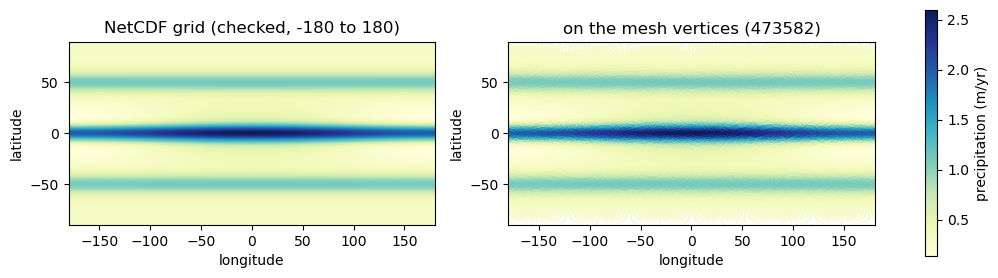

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].pcolormesh(grid.lon, grid.lat, grid, shading="auto", cmap="YlGnBu")
ax[0].set_title("NetCDF grid (checked, -180 to 180)")
sc = ax[1].scatter(lon, lat, c=rain, s=0.2, cmap="YlGnBu", rasterized=True)
ax[1].set_title("on the mesh vertices (%d)" % len(lon))
for a in ax:
    a.set_xlim(-180, 180); a.set_ylim(-90, 90); a.set_aspect("equal")
    a.set_xlabel("longitude"); a.set_ylabel("latitude")
fig.colorbar(sc, ax=ax, shrink=0.8, label="precipitation (m/yr)")
plt.show()

## 4. When the grid is not well formed

Each case below is a common problem; the message gives the fix, applied right after.

In [6]:
def show(da):
    try:
        md.check_global_grid(da)
        print("OK")
    except md.GridError as err:
        print(err)

g = grid
cases = {
    "cell-centred longitudes (-179.75 to 179.75)": g.interp(lon=np.arange(-179.75, 180., 0.5)),
    "no poles (-89.75 to 89.75)": g.interp(lat=np.arange(-89.75, 90., 0.5)),
    "latitudes from north to south": g.sortby("lat", ascending=False),
    "other coordinate names": g.rename({"lon": "LONGXY", "lat": "LATIXY"}),
    "a time dimension": g.expand_dims(time=[2000, 2001]),
    "missing values over the sea": g.where(g > 0.5),
}
for name, da in cases.items():
    print("--", name)
    show(da)
    print()

-- cell-centred longitudes (-179.75 to 179.75)
Longitudes run from -179.75 to 179.75: the grid must include both -180 and 180 (or 0 and 360).
A cell-centred grid stops half a cell short. Fix: close it with the opposite column,
  da = xr.concat([da.isel(lon=-1).assign_coords(lon=-180.), da,
                  da.isel(lon=0).assign_coords(lon=180.)], dim='lon')
and interpolate the two edge columns if you need them exact.

-- no poles (-89.75 to 89.75)
Latitudes run from -89.75 to 89.75: the grid must include both poles (-90 and 90).
A cell-centred grid stops half a cell short. Fix: add the poles, e.g.
  da = da.interp(lat=np.r_[-90., da.lat.values, 90.], kwargs={'fill_value': 'extrapolate'})
or, to repeat the last row:  da = da.pad(lat=1, mode='edge').assign_coords(lat=np.r_[-90., da.lat.values, 90.])

-- latitudes from north to south
Latitudes decrease (90 to -90).
Fix: da = da.sortby('lat')

-- other coordinate names
No longitude coordinate found (looked for lon, longitude, long, x); th

Applying the fixes the messages give:

In [7]:
cc = cases["cell-centred longitudes (-179.75 to 179.75)"]
fixed = xr.concat([cc.isel(lon=-1).assign_coords(lon=-180.), cc,
                   cc.isel(lon=0).assign_coords(lon=180.)], dim="lon")
show(fixed)

npl = cases["no poles (-89.75 to 89.75)"]
show(npl.interp(lat=np.r_[-90., npl.lat.values, 90.], kwargs={"fill_value": "extrapolate"}))

show(cases["latitudes from north to south"].sortby("lat"))
show(cases["other coordinate names"].rename({"LONGXY": "lon", "LATIXY": "lat"}))
show(cases["a time dimension"].isel(time=0))
show(cases["missing values over the sea"].fillna(0.))

OK
OK
OK
OK
OK
OK


## 5. Several maps at once

The same steps for each field, saved in one `npz` (each a `[file, key]` in the input file).
Use `method="nearest"` for integer classes (a provenance or lithology map).

In [8]:
fields = {"r": ("demo_precip_0_360.nc", "precip", "linear")}   # key: (file, variable, method)
maps = {k: md.interpolate_to_mesh(md.open_global_grid(f, var=v), lon, lat, method=m)
        for k, (f, v, m) in fields.items()}
np.savez("forcing_mesh.npz", **maps)
print({k: (round(float(a.min()), 3), round(float(a.max()), 3)) for k, a in maps.items()})

{'r': (0.133, 2.6)}
